# Initial Conditions

Device: Google Colab free T4 GPU

# Experiment

In [ ]:
# !pip install tqdm

Import dependencies

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.nn import CrossEntropyLoss
import torchvision
from torchvision import transforms
import torchvision.models as models
from tqdm import tqdm
from torchsummary import summary
import numpy as np

# reproducibility
torch.manual_seed(0)
np.random.seed(0)

Define constants

In [ ]:
SAVE_PATH = "checkpoint.pth"
BATCH_SIZE = 32
IMG_DIM_X = 64
IMG_DIM_Y = 64
MAX_EPOCHS = 30

# Label dictionary
label_map = {
    0: "AnnualCrop",
    1: "Forest",
    2: "HerbaceousVegetation",
    3: "Highway",
    4: "Industrial",
    5: "Pasture",
    6: "PermanentCrop",
    7: "Residential",
    8: "River",
    9: "SeaLake"
}

known_labels = {
    0, 1, 3, 4, 5, 7, 9
}


Use CUDA GPU if available

In [ ]:
  device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
  # device = torch.device('cpu')
  if torch.cuda.is_available():
    print("You are running on cuda GPU")
  else:
    print("You are running on CPU")

You are running on cuda GPU


Define transforms to apply on images

In [ ]:
  transform = transforms.Compose([
      transforms.ToTensor(),
      transforms.RandomCrop((IMG_DIM_X,IMG_DIM_Y)),
      transforms.RandomHorizontalFlip(),
      transforms.RandomVerticalFlip(),
      transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
  ])

Load dataset

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# !cat eurosat.zip
!cp "/content/drive/MyDrive/EuroSAT.zip" "/content/EuroSAT.zip"

In [ ]:
!unzip "/content/EuroSAT.zip"

Streaming output truncated to the last 5000 lines.
  inflating: EuroSAT/River/River_2120.jpg  
  inflating: EuroSAT/River/River_2126.jpg  
  inflating: EuroSAT/River/River_2134.jpg  
  inflating: EuroSAT/River/River_2137.jpg  
  inflating: EuroSAT/River/River_2139.jpg  
  inflating: EuroSAT/River/River_214.jpg  
  inflating: EuroSAT/River/River_2141.jpg  
  inflating: EuroSAT/River/River_2144.jpg  
  inflating: EuroSAT/River/River_2146.jpg  
  inflating: EuroSAT/River/River_2147.jpg  
  inflating: EuroSAT/River/River_2148.jpg  
  inflating: EuroSAT/River/River_2149.jpg  
  inflating: EuroSAT/River/River_215.jpg  
  inflating: EuroSAT/River/River_2151.jpg  
  inflating: EuroSAT/River/River_2152.jpg  
  inflating: EuroSAT/River/River_2154.jpg  
  inflating: EuroSAT/River/River_2161.jpg  
  inflating: EuroSAT/River/River_2164.jpg  
  inflating: EuroSAT/River/River_2165.jpg  
  inflating: EuroSAT/River/River_2169.jpg  
  inflating: EuroSAT/River/River_217.jpg  
  inflating: EuroSAT/River/R

In [ ]:
import os
import pandas as pd
from PIL import Image
from torch.utils.data import Dataset
from torchvision import transforms
import pdb


class EuroSAT(Dataset):
    def __init__(self, csv_file, root_dir, transform=None):
        self.data = pd.read_csv(csv_file)
        self.root_dir = root_dir
        self.transform = transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        img_rel_path = self.data.iloc[idx]['Filename']

        if (self.data.iloc[idx]['Label'] in known_labels):
            known = 1
        else:
            known = 0

        label = self.data.iloc[idx]['Label']

        img_path = os.path.join(self.root_dir, img_rel_path)

        image = Image.open(img_path).convert("RGB")

        if self.transform:
            image = self.transform(image)

        return image, label, known


In [ ]:
def load_data(transform):
    root_dir = "/content/EuroSAT"

    train_csv = os.path.join(root_dir, "train_filtered.csv")
    val_csv = os.path.join(root_dir, "validation.csv")
    test_csv = os.path.join(root_dir, "test.csv")

    train_set = EuroSAT(csv_file=train_csv, root_dir=root_dir, transform=transform)
    val_set = EuroSAT(csv_file=val_csv, root_dir=root_dir, transform=transform)
    test_set = EuroSAT(csv_file=test_csv, root_dir=root_dir, transform=transform)

    # Create data loaders
    train_loader = torch.utils.data.DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True)
    val_loader = torch.utils.data.DataLoader(val_set, batch_size=BATCH_SIZE, shuffle=True)
    test_loader = torch.utils.data.DataLoader(test_set, batch_size=BATCH_SIZE, shuffle=False)  # No need to shuffle test set

    return train_loader, val_loader, test_loader

train_loader, val_loader, test_loader = load_data(transform=transform)

Define model

In [ ]:
class SmallCNN(nn.Module):
    def __init__(self, num_classes=10):
        super(SmallCNN, self).__init__()

        self.network = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size = 3, padding = 1),
            nn.ReLU(),
            nn.MaxPool2d(2,2),
            nn.Conv2d(32, 64, kernel_size = 3, padding = 1),
            nn.ReLU(),
            nn.MaxPool2d(4,4),
            nn.Flatten(),
            nn.Linear(4096, num_classes)
        )

    def forward(self, x):
        return self.network(x)

# Instantiate the model and define input shape
model = SmallCNN(num_classes=10).to(device)

# Test the model with random input
dummy_input = torch.randn(1, 3, IMG_DIM_X, IMG_DIM_Y).to(device) # Batch size 1, 3 color channels, dimensions of image
output = model(dummy_input)
print(output.shape)  # Expected output shape: [1, 10]

# MODEL SOURCE: https://medium.com/thecyphy/train-cnn-model-with-pytorch-21dafb918f48

torch.Size([1, 10])


In [ ]:
model_tmp = SmallCNN().to(device)
summary(model_tmp, input_size=(3, IMG_DIM_X, IMG_DIM_Y))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 32, 64, 64]             896
              ReLU-2           [-1, 32, 64, 64]               0
         MaxPool2d-3           [-1, 32, 32, 32]               0
            Conv2d-4           [-1, 64, 32, 32]          18,496
              ReLU-5           [-1, 64, 32, 32]               0
         MaxPool2d-6             [-1, 64, 8, 8]               0
           Flatten-7                 [-1, 4096]               0
            Linear-8                   [-1, 10]          40,970
Total params: 60,362
Trainable params: 60,362
Non-trainable params: 0
----------------------------------------------------------------
Input size (MB): 0.05
Forward/backward pass size (MB): 3.31
Params size (MB): 0.23
Estimated Total Size (MB): 3.59
----------------------------------------------------------------


Train

In [ ]:
def epoch(model, device, loader, criterion, optimizer, validate=False):
    epoch_loss = 0
    n = 0

    if (validate == True):
        model.eval()
        context = torch.no_grad()
    else:
        model.train()
        context = torch.enable_grad()

    with context:
      for data, labels, known in tqdm(loader):
          data, labels, known = data.to(device), labels.to(device), known.to(device)

          if (validate == False):
            # Clear the gradients
            optimizer.zero_grad()

          # Forward Pass
          target = model(data).to(device)
          # Find the Loss
          loss = criterion(target,labels)
          epoch_loss += loss.item() * data.size(0)

          if (validate == False):
            # Calculate gradients
            loss.backward()
            # Update Weights
            optimizer.step()

          n = n + 1

    epoch_loss /= len(loader.dataset)

    return epoch_loss

In [ ]:
import time
training_start_time = time.time()

def train(model, device, train_loader, val_loader, criterion, optimizer, epochs):
  print("Training initialized")

  loss_values = {
      'train': [],
      'valid': []
  }

  patience = 5 # Number of epochs to wait before stopping
  min_delta = 0.01 # Minimum change in loss to qualify as an improvement
  patience_counter = 0
  best_loss = float('inf')

  for e in range(epochs):
    loss_train = epoch(model, device, train_loader, criterion, optimizer)
    loss_values['train'].append(loss_train)
    print(f"loss_train: {loss_train:.2f}")

    loss_valid = epoch(model, device, val_loader, criterion, optimizer, validate=True)
    loss_values['valid'].append(loss_valid)
    print(f"loss_valid: {loss_valid:.2f}, best_loss: {best_loss:.2f}")

    # Check for improvement
    if loss_valid < best_loss - min_delta:
        best_loss = loss_valid
        patience_counter = 0
    else:
        patience_counter += 1
        if patience_counter >= patience:
            print(f"Early stopping at epoch {e}")
            break

  return loss_values


criterion=torch.nn.CrossEntropyLoss()
optimizer=torch.optim.Adam(model.parameters(), lr=0.001)
loss_values = train(model, device, train_loader, val_loader, criterion, optimizer, MAX_EPOCHS)

torch.save(model.state_dict(), SAVE_PATH) # Save model
print('Total training time: {:.2f}s'.format(time.time() - training_start_time))

# https://cyborgcodes.medium.com/what-is-early-stopping-in-deep-learning-eeb1e710a3cf

In [ ]:
import matplotlib.pyplot as plt

loss_values['train'] = loss_values['train'][1:]
loss_values['valid'] = loss_values['valid'][:-1]

# plt.xticks(range(1,len(loss_values)))
plt.plot(loss_values['train'], label="Train")
plt.plot(loss_values['valid'], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training Loss")
plt.legend()
plt.show()

NameError: name 'loss_values' is not defined

In [ ]:
model.load_state_dict(torch.load("/content/openset_classification_experiment_2025_06_22.pth", weights_only=True))

<All keys matched successfully>

Choosing a threshold

In [ ]:
def validate(model, device, loader, criterion):
  model.eval()

  y_true = []
  y_score = []
  known_true = []

  # Evaluate test dataset
  with torch.no_grad(): # don't calculate gradient
    for x, y, known in tqdm(loader):
      x = x.to(device)

      y_hat = model(x)

      mls = np.max(y_hat.cpu().numpy(), axis=1)

      y_true.extend(y.numpy())
      y_score.extend(mls)
      known_true.extend(known.numpy())

  return y_true, y_score, known_true

In [ ]:
val_y_true, val_y_score, val_known_true = validate(model, device, val_loader, criterion)

100%|██████████| 169/169 [00:05<00:00, 29.19it/s]


In [ ]:
from sklearn.metrics import precision_recall_curve, average_precision_score

precision, recall, thresholds = precision_recall_curve(val_known_true, val_y_score)
ap = average_precision_score(val_known_true, val_y_score)

f1_scores = 2 * (precision * recall) / (precision + recall + 1e-8)

best_idx = f1_scores[:-1].argmax()
best_threshold = thresholds[best_idx]
best_f1 = f1_scores[best_idx]

print(f"Best threshold = {best_threshold:.4f}")
print(f"F1 score at best threshold = {best_f1:.4f}")

Best threshold = 3.0051
F1 score at best threshold = 0.8901


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

import numpy as np
import matplotlib.pyplot as plt

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

def plot_pr_curve(precision, recall, thresholds, ap, highlight_threshold):
    fig, ax = plt.subplots(figsize=(7, 5))

    # 1) PR curve
    ax.plot(recall, precision, label=f"PR Curve (AP = {ap:.2f})", color='tab:blue')

    # 2) Highlight point & guide-lines
    idx = np.argmin(np.abs(thresholds - highlight_threshold))
    r0, p0, t0 = recall[idx], precision[idx], thresholds[idx]
    ax.plot(r0, p0, 'o', color='red', markersize=8, label=f"Thr ≈ {t0:.3f}")
    ax.axvline(r0, color='red', linestyle=':', linewidth=1, alpha=0.7, zorder=0)
    ax.axhline(p0, color='red', linestyle=':', linewidth=1, alpha=0.7, zorder=0)

    # 3) Annotate coordinates
    ax.annotate(
        f"({r0:.2f}, {p0:.2f})",
        xy=(r0, p0),
        xytext=(r0 + 0.03, p0 + 0.02),
        arrowprops=dict(arrowstyle="->", color="red"),
        color="red",
        fontsize=9,
        bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.8),
    )

    # 4) Labels, title, grid
    ax.set_xlabel("Recall")
    ax.set_ylabel("Precision")
    ax.set_title("Precision-Recall Curve")
    ax.legend(loc='lower left', frameon=False)
    ax.grid(which='major', linestyle='--', alpha=0.4)
    ax.grid(which='minor', linestyle=':', alpha=0.2)

    # 5) Ticks and limits
    ax.set_xlim(0.0, 1.0)
    ax.set_ylim(precision.min() - 0.02, 1.02)

    # Major ticks every 0.2, minor every 0.05
    ax.xaxis.set_major_locator(MultipleLocator(0.2))
    ax.xaxis.set_minor_locator(MultipleLocator(0.05))
    ax.yaxis.set_major_locator(MultipleLocator(0.1))
    ax.yaxis.set_minor_locator(MultipleLocator(0.02))

    # 6) Top axis for thresholds (unchanged)
    ax_top = ax.twiny()
    ax_top.set_xlim(ax.get_xlim())
    # Pick about 8 evenly spaced thresholds:
    N = len(thresholds)
    sel = np.linspace(0, N-2, 8, dtype=int)   # drop last recall point
    ax_top.set_xticks(recall[sel])
    ax_top.set_xticklabels([f"{thresholds[i]:.2f}" for i in sel], rotation=90, fontsize=8)
    ax_top.set_xlabel("Threshold", labelpad=10)

    plt.tight_layout()
    plt.show()




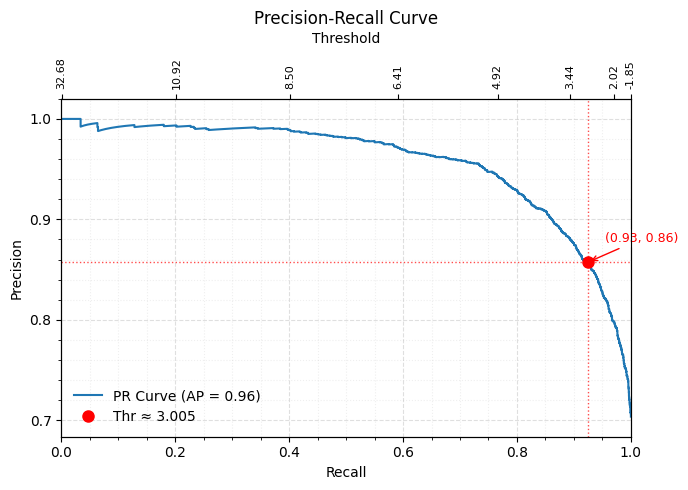

In [ ]:
# plot_pr_curve(precision, recall, ap)
plot_pr_curve(precision, recall, thresholds, ap, best_threshold)

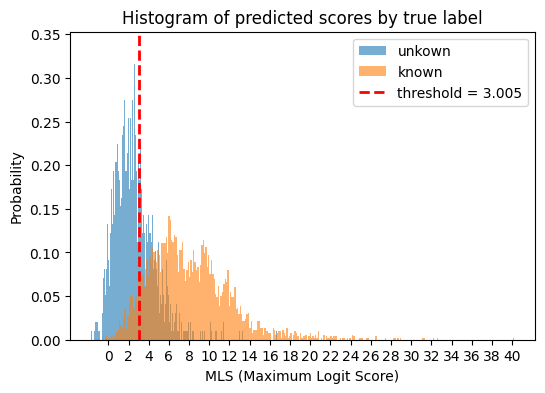

In [ ]:
def plot_hist(known_true, y_score, threshold, bins=300):
  known_true = np.asarray(known_true)
  y_score = np.asarray(y_score)

  fig, ax = plt.subplots(figsize=(6, 4))

  pos_mask = known_true == 1
  neg_mask = known_true == 0

  ax.hist(y_score[neg_mask], bins=bins, alpha=0.6, label="unkown", density=True)
  ax.hist(y_score[pos_mask], bins=bins, alpha=0.6, label="known", density=True)

  ax.axvline(threshold,
            color="red", linestyle="--", linewidth=2,
            label=f"threshold = {threshold:.3f}")

  ax.set_xticks(np.arange(0, 41, 2))

  ax.set_xlabel("MLS (Maximum Logit Score)")
  ax.set_ylabel("Probability")
  ax.set_title("Histogram of predicted scores by true label")
  ax.legend()
  plt.show()

plot_hist(known_true, y_score, best_threshold)

Evaluate

In [ ]:
def evaluate(model, device, loader, criterion, best_threshold):
  model.eval()

  known_true = []
  known_pred = []
  y_true = []
  y_pred = []

  # Evaluate test dataset
  with torch.no_grad():
    for x, y, known in tqdm(loader):
      x = x.to(device)

      y_hat = model(x)

      mls = np.max(y_hat.cpu().numpy(), axis=1)

      known_true.extend(known.numpy())
      known_pred.extend((mls > best_threshold).astype(int))
      y_true.extend(y.cpu())
      y_pred.extend(np.argmax(y_hat.cpu(), axis=1))

  known_true = np.array(known_true)
  known_pred = np.array(known_pred)
  y_true = np.array(y_true)
  y_pred = np.array(y_pred)

  # filter class prediction where class is unknown
  mask = (known_true != 0)
  y_true_filtered = y_true[mask]
  y_pred_filtered = y_pred[mask]

  return np.array(known_true), np.array(known_pred), np.array(y_true_filtered), np.array(y_pred_filtered)

In [ ]:
eval_known_true, eval_known_pred, eval_y_true, eval_y_pred= evaluate(model, device, test_loader, criterion, best_threshold)

100%|██████████| 85/85 [00:02<00:00, 34.80it/s]


In [ ]:
from sklearn.metrics import classification_report

report = classification_report(eval_known_true, eval_known_pred, target_names=['unkown', 'known'])
print("Closed-set report")
print(report)

target_names = [label_map[i] for i in known_labels]

report = classification_report(eval_y_true, eval_y_pred, target_names=target_names)
print("Open-set report")
print(report)

Closed-set report
              precision    recall  f1-score   support

      unkown       0.76      0.66      0.70       800
       known       0.86      0.91      0.89      1900

    accuracy                           0.84      2700
   macro avg       0.81      0.78      0.80      2700
weighted avg       0.83      0.84      0.83      2700

Open-set report
              precision    recall  f1-score   support

  AnnualCrop       0.94      0.95      0.95       300
      Forest       0.99      0.96      0.97       300
     Highway       0.90      0.90      0.90       250
  Industrial       0.96      0.96      0.96       250
     Pasture       0.94      0.90      0.92       200
 Residential       0.99      0.98      0.98       300
     SeaLake       0.93      0.99      0.96       300

    accuracy                           0.95      1900
   macro avg       0.95      0.95      0.95      1900
weighted avg       0.95      0.95      0.95      1900

